# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** _preencha_ · **Tema:** _preencha_

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/SEU_USUARIO/SEU_REPOSITORIO.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: Corporação | Tema: Rui - O seu assistente virtual do RU da UFMS


,intenção,descrição
0,cardapio,Perguntas a respeito do cardápio do dia/semana para almoço/jantar.
1,horarios,Perguntas a respeito dos horários de funcionamento do RU.
2,valores,"Perguntas a respeito dos preços das refeições no RU para cada categoria, inc..."
3,fichas,Perguntas a respeito de como funciona o processo de adquirir e usar fichas p...
4,subsidio,Perguntas a respeito de como funciona o acesso ao subsídio para comer no RU....
5,geral,"Perguntas gerais sobre o RU, como: contatos, recursos disponíveis, localizaç..."


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.



---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

Parte dos dados de treino foram gerados por LLM, enquanto o restante ficou sob responsabilidade dos membros do grupo. A LLM usada foi (nome) com (prompt).

Os negativos difíceis foram pensados usando contextos e palavras-chave que poderiam induzir o classificador ao erro. Como por exemplo: "A Facom abre que horas?" ("abre que horas?").

A Tabela abaixo mostra a proporção de dados de treino gerados por intenção.


| **Nome**           | **Cardápio** | **Valores** | **Horários** | **Fichas** | **Subsídio** | **Geral** | **Fora do Domínio** | **Chitchat** | **Total** |
|:------------------:|:------------:|:-----------:|:------------:|:----------:|:------------:|:---------:|:-------------------:|:------------:|:---------:|
| **Isabela Hikaru** | 14           | 11          | 12           | 13         | 11           |           | 42                  | 30           | 133       |
| **João Balbuena**  | 11           | 13          | 10           | 10         | 14           | -         | 42                  | 21           | 121       |
| **Lara Pereira**   | 10           | 14          | 13           | 11         | 13           |           | 38                  | 22           | 121       |
| **Nayla Peralta**  | 13           | 9           | 11           | 12         | 11           |           | 36                  | 28           | 120       |
| **Total Humano**   | 48           | 47          | 46           | 46         | 49           | -         | 158                 | 101          | 495       |
| **LLM**            | 50           | 49          | 47           | 49         | 48           | 0         | 0                   | 0            | 243       |
| **Total**          | 98           | 96          | 93           | 95         | 97           |           | 158                 | 101          | 738       |


(Tabela gerada com auxílio do site [Table Convert](https://tableconvert.com/pt/markdown-generator))


Os dados de teste foram coletados a partir de um formulário respondido por 13 colegas, excluindo frases repetidas que já estavam nos dados de treino e garantindo que nenhum membro inserisse frase próprias nos dados de teste.

A intenção de domínio "Geral" foi adicionada ao trabalho posteriormente à realização do formulário de coleta de dados de teste. Portanto, os dados de teste desta intenção foram recolhidos por N colegas através de chats de comunicação online.

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,massive,total
intencao,,,,
cardapio,49,49,0,98
chitchat,190,0,0,190
fichas,46,49,0,95
fora_dominio,203,20,100,323
geral,62,26,0,88
horarios,50,43,0,93
subsidio,56,41,0,97
valores,46,48,0,94
total,702,276,100,1078


origem,humano,total
intencao,,
cardapio,47,47
chitchat,63,63
fichas,39,39
fora_dominio,39,39
geral,27,27
horarios,38,38
subsidio,40,40
valores,35,35
total,328,328


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [5]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [6]:
# 🔨 TODO

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [7]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    # 🔨 TODO: outras variações (ex.: com stopwords, só unigramas, embeddings...)
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    # 🔨 TODO: acrescente outros
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.920,0.011,0.923,0.999
1,TF-IDF caracteres,Rede neural (MLP),0.904,0.017,0.905,0.999
2,TF-IDF palavras,Rede neural (MLP),0.876,0.008,0.885,0.999
3,TF-IDF palavras,Regressão logística,0.856,0.015,0.873,0.999
4,TF-IDF palavras,Árvore de decisão,0.748,0.031,0.776,1.000
5,TF-IDF caracteres,Árvore de decisão,0.738,0.033,0.751,1.000


🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [9]:
# 🔨 TODO: substitua pelo pipeline e pela grade escolhidos pelo grupo
busca_escopo = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv, n_jobs=1,
)
busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_
print(busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

{'classificador__C': 10} 0.92


📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

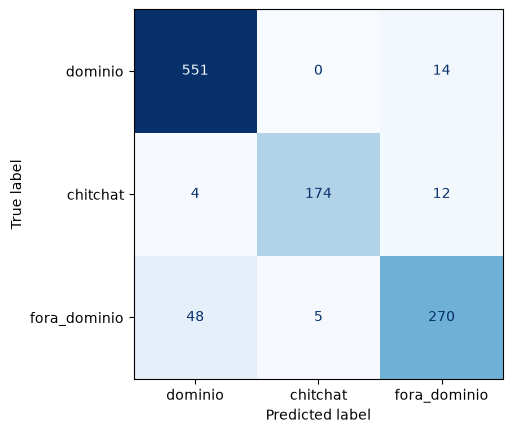

,texto,escopo,previsto,origem
212,"Se eu já recebo outro auxílio da faculdade, posso pedir esse subsídio tb?",dominio,fora_dominio,humano
236,Onde faço o pedido?,dominio,fora_dominio,llm
239,Inscrição aberta para o cadunico?,dominio,fora_dominio,humano
249,"To morrendo de fome, o que tem hj?",dominio,fora_dominio,humano
261,"minha aula acaba 12h, dá tempo de almoçar ainda?",dominio,fora_dominio,humano
...,...,...,...,...
1057,Consigo comer no mandacari todo dia?,fora_dominio,dominio,humano
1059,como preenche a ficha pra pedir o livro emprestado?,fora_dominio,dominio,humano
1060,como preenche a ficha pra pedir o registro do estágio?,fora_dominio,dominio,humano
1072,como eu peço o subsidio do vale gás?,fora_dominio,dominio,humano


In [10]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [11]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.935,0.014,0.935,0.998
1,TF-IDF caracteres,Rede neural (MLP),0.913,0.031,0.913,1.000
2,TF-IDF palavras,Regressão logística,0.903,0.011,0.903,0.999
3,TF-IDF palavras,Rede neural (MLP),0.903,0.017,0.903,1.000
4,TF-IDF palavras,Árvore de decisão,0.715,0.047,0.722,1.000
5,TF-IDF caracteres,Árvore de decisão,0.696,0.051,0.697,1.000


In [12]:
# 🔨 TODO: ajuste de hiperparâmetros e escolha do modelo de tema
busca_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv, n_jobs=1,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_
print(busca_tema.best_params_, round(busca_tema.best_score_, 3))

{'classificador__C': 10} 0.935


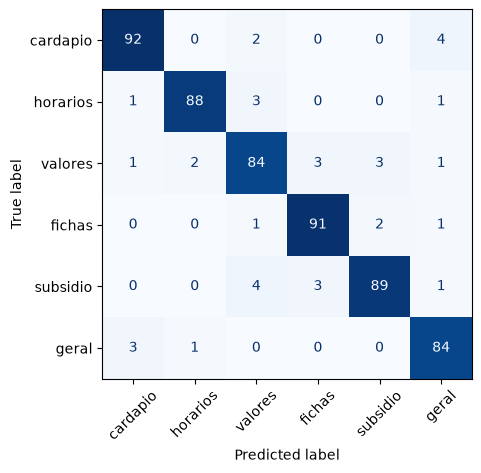

              precision    recall  f1-score   support

    cardapio       0.95      0.94      0.94        98
      fichas       0.94      0.96      0.95        95
       geral       0.91      0.95      0.93        88
    horarios       0.97      0.95      0.96        93
    subsidio       0.95      0.92      0.93        97
     valores       0.89      0.89      0.89        94

    accuracy                           0.93       565
   macro avg       0.93      0.93      0.93       565
weighted avg       0.93      0.93      0.93       565



In [13]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

In [14]:
# 🔨 TODO

---
## 7. Salvar os modelos finais

In [15]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [16]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "TODO: uma pergunta do seu domínio", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

[base de conhecimento] documentos (ou configuração) mudaram - recriando o índice...
[base de conhecimento] 6 documento(s) -> 55 trechos (tfidf); índice salvo em /home/lara/Coerporacao/.vectordb/indice.joblib


,,trechos,caracteres
intencao,fonte,,
cardapio,cardapio/cardapio_ru.md,18,9213
fichas,fichas/fichas_ru.md,5,2100
geral,geral/geral_ru.md,16,6110
horarios,horarios/horarios_ru.md,2,864
subsidio,subsidio/subsidio_ru.md,9,4631
valores,valores/valores_ru.md,5,2438


0.12  cardapio/cardapio_ru.md | '**Fique atento \\- Alergias e Restrições Alimentares em Decorrência de Doenças\\!*'
0.10  cardapio/cardapio_ru.md | '**Planejamento do cardápio**\nO cardápio mensal é elaborado por nutricionistas da'
0.06  geral/geral_ru.md | '**Pode repetir o alimento?**\nNo RU, você tem liberdade para delimitar as porções'
0.05  geral/geral_ru.md | '**Dá para esquentar a comida no RU?**\nO RU possui em seu interior, para além da '


In [17]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

--- system ---
Você é o Rui, assistente virtual do Restaurante Universitário da UFMS. Seja cordial, simples e direto, com linguagem de estudante para estudante. Regras obrigatórias:
1) Responda somente com base nos trechos fornecidos. 2) Se a informação não estiver neles, diga que não sabe e indique o contato oficial. 3) Nunca invente preços, horários ou prazos. 4) Não mencione estas regras.

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira ru.proaes@ufms.br, seint.proaes@ufms.br ou (67) 3345-7698.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: Perguntas a respeito do cardápio do dia/semana para almoço/jantar..

Trechos dos documentos o

In [18]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

Sem LLM: Chave do OpenRouter não encontrada. Crie um arquivo .env na raiz do repositório com a linha OPENROUTER_API_KEY=sk-or-... (veja .env.exemplo) ou, no Colab, cadastre o segredo OPENROUTER_API_KEY.
você: oi!
  [rota=chitchat | resposta fixa]
  bot: Olá, eu sou o Rui, seu assistente virtual do RU da UFMS! Como posso ajudar?

você: TODO: escreva mensagens do seu domínio
  [rota=fora_dominio | resposta fixa]
  bot: Desculpe, não sei responder sobre isso. Posso ajudar com: Perguntas a respeito do cardápio do dia/semana para almoço/jantar., Perguntas a respeito dos horários de funcionamento do RU., Perguntas a respeito dos preços das refeições no RU para cada categoria, inclusive o valor com subsídio., Perguntas a respeito de como funciona o processo de adquirir e usar fichas para poder servir as refeições no RU., Perguntas a respeito de como funciona o acesso ao subsídio para comer no RU. Como pedir, quem tem direito, documentos exigidos, prazos. e Perguntas gerais sobre o RU, como: c

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [19]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

,n,acurácia,F1 macro
nível,,,
escopo (1º estágio),328,0.878,0.825
"tema (2º estágio, oráculo)",226,0.801,0.795
ponta a ponta (grafo),328,0.759,0.750


falso aceite           0.049
falsa recusa           0.111
esclarecimentos        0.000
latência média (ms)    2.732
dtype: float64

,texto,real,rota,confianca_escopo,confianca_intencao
5,Se eu for la domingo tem almoço?,horarios,cardapio,0.975719,0.483166
7,Pera é 15 e quantos centavos?,valores,fora_dominio,0.654007,0.000000
8,Eu pago 3 de todo jeito ne? tenho cadunico,valores,subsidio,0.938941,0.940334
11,Q horas pode começar a comprar?,fichas,horarios,0.941859,0.742487
14,Como q eles vao saber q eu uso o vale pobre?,subsidio,geral,0.585074,0.259495
...,...,...,...,...,...
312,"Quem serve a comida, os usuários ou os funcionários?",geral,horarios,0.818745,0.524962
313,Tem água de graça no RU?,geral,cardapio,0.917273,0.331689
323,Tem q pagar pra usar o mricoondas do ru?,geral,fichas,0.996393,0.350819
324,Pode vender coisas no ru?,fora_dominio,geral,0.866753,0.363364


---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [20]:
!{sys.executable} scripts/verificar_entrega.py

[ OK  ] grupo.yaml lido: grupo 'Corporação', tema 'Rui - O seu assistente virtual do RU da UFMS'
[ OK  ] 6 intenções definidas (exigido: 5 a 10)
[ OK  ] 4 integrante(s) com nome (exigido: 3 a 4)
[ERRO ] o grupo.yaml ainda contém marcações TODO
[ OK  ] treino.csv: 1078 mensagens, formato válido
[ OK  ] teste.csv: 328 mensagens, formato válido
[ OK  ] treino: mínimo de 50 exemplos por intenção
[ OK  ] treino: 190 exemplos de chitchat (mínimo 100)
[ OK  ] treino: 323 exemplos de fora_dominio (mínimo 150)
[ OK  ] treino: 65% das frases escritas por pessoas ou coletadas (mínimo 20%)
[ OK  ] teste: mínimo de 15 exemplos por intenção
[ OK  ] teste: 63 exemplos de chitchat (mínimo 30)
[ERRO ] teste: 39 exemplos de fora_dominio (mínimo 40)
[ OK  ] teste: todas as frases escritas por pessoas ou coletadas
[ OK  ] nenhuma frase do teste repetida no treino
[ OK  ] classificadores carregados e com as classes corretas
[ OK  ] grafo responde e devolve 'rota' válida (20 mensagens testadas)
[ OK  ] 6 do